# Actividad: Optimización y Regularización de Redes Neuronales

**Grupo 7**
- Agustín Fernández
- Sebastián Salgado
- Eduardo Uribe

**Asignatura:** Técnicas de Machine Learning I (TLY1102)  
**Fecha:** Octubre 2026



---

## 1. Introducción

Esta actividad compara tres arquitecturas de perceptrón multicapa (MLP) para clasificar dígitos manuscritos del dataset MNIST (10 clases, de 0 a 9). Cada modelo usa Dropout para regularizar y EarlyStopping para detener el entrenamiento cuando la pérdida de validación deja de mejorar.

### Objetivos
1. Comprender el impacto del entrenamiento diferido mediante EarlyStopping combinado con Dropout.
2. Evaluar cómo varía la capacidad de generalización al modificar la complejidad de la red (número de capas y neuronas).
3. Establecer criterios cuantitativos (umbrales mínimos) para seleccionar el modelo óptimo.

### Criterios de aceptación

Un modelo es aceptable si cumple los tres criterios mínimos:

| Criterio | Umbral | Cómo se mide |
|---|---|---|
| 1. Precisión de validación | `val_accuracy` ≥ 0,975 (97,5 %) | Accuracy sobre el conjunto de validación, con los mejores pesos restaurados |
| 2. Brecha de sobreajuste | (Train accuracy − Val accuracy) ≤ 0,015 (1,5 %) | Misma medición, con los mejores pesos |
| 3. Eficiencia | Detención temprana antes de la época 30 | Número de épocas ejecutadas < 30 |


### Decisiones de implementación

| Decisión | Detalle | Justificación |
|---|---|---|
| Dataset | MNIST: 60 000 imágenes de entrenamiento y 10 000 de prueba | Es el dataset indicado en el PDF de la actividad. |
| Partición | 90 % entrenamiento / 10 % validación, estratificada; prueba original sin cambios | La validación conserva la proporción de clases y la prueba se reserva para la evaluación final. |
| Batch size | 64 | Configuración de la corrida presentada en esta versión. |
| EarlyStopping | `val_loss`, paciencia 3, `restore_best_weights=True`, máximo 30 épocas | Criterio del PDF; los pesos finales son los de la mejor época. |
| Optimizador | Adam, learning rate 0,001 | Valor por defecto de Adam. |
| Normalización | Píxeles / 255 → rango [0, 1] | Deja todas las entradas en la misma escala. |


# 2. Conceptos

Dropout apaga aleatoriamente una fracción de las neuronas durante el entrenamiento. Esto obliga a la red a no depender siempre de las mismas neuronas, lo que mejora su capacidad de generalizar y reduce el sobreajuste (overfitting). Durante la evaluación, todas las neuronas están activas.

**EarlyStopping** detiene el entrenamiento cuando la pérdida de validación (val_loss) deja de mejorar durante patience épocas. Con restore_best_weights=True, el modelo conserva los pesos de la mejor época y no los de la última.

**Parámetros clave de EarlyStopping:**
- monitor='val_loss': observa la pérdida de validación.
- patience=3: permite 3 épocas sin mejora antes de detener.
- restore_best_weights=True: se queda con los pesos de la mejor época, no con los de la última.

**Observación:** sparse_categorical_crossentropy se usa cuando el problema es multiclase y las etiquetas son enteros (0 a 9). Si las etiquetas estuvieran codificadas como one-hot, se usaría categorical_crossentropy.

| Función | Formato esperado de las etiquetas | Ejemplo de `y_train` |
|---|---|---|
| `categorical_crossentropy` | One-hot (vectores binarios) | [0, 1, 0, 0, 0] |
| `sparse_categorical_crossentropy` | Enteros (una clase por muestra) | 2 |

# 3. Imports y configuracion

In [ ]:
import random
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# 4. Carga de datos

El dataset MNIST se descarga automáticamente con Keras la primera vez: 60 000 imágenes de entrenamiento y 10 000 de prueba, cada una de 28 × 28 píxeles en escala de grises.

In [ ]:

(X_full, y_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Entrenamiento original:", X_full.shape, "| Prueba:", X_test.shape)

Entrenamiento original: (60000, 28, 28) | Prueba: (10000, 28, 28)


# 5. Normalización y partición

1. **Normalización:** píxeles / 255 → rango [0, 1]. Se agrega el canal de escala de grises: (28, 28) → (28, 28, 1).
2. **Validación:** 10 % del entrenamiento, estratificada. El conjunto de prueba original no se modifica.

In [ ]:

X_full = (X_full / 255.0).reshape(-1, 28, 28, 1).astype("float32")
X_test = (X_test / 255.0).reshape(-1, 28, 28, 1).astype("float32")


idx = np.arange(len(X_full))
idx_train, idx_val = train_test_split(idx, test_size=0.10, random_state=42, stratify=y_full)
X_train, y_train = X_full[idx_train], y_full[idx_train]
X_val, y_val = X_full[idx_val], y_full[idx_val]

NUM_CLASSES = 10
EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 0.001

print("Clases:", NUM_CLASSES)
print("Entrenamiento:", X_train.shape, "| Validacion:", X_val.shape, "| Prueba:", X_test.shape)

Clases: 10
Entrenamiento: (54000, 28, 28, 1) | Validación: (6000, 28, 28, 1) | Prueba: (10000, 28, 28, 1)


**5.1 Verificación de la partición:** entrenamiento y validación no deben compartir filas.

In [ ]:
assert set(idx_train).isdisjoint(set(idx_val)), "Hay filas compartidas entre entrenamiento y validacion"
print("Sin solapamiento entre entrenamiento y validacion:", set(idx_train).isdisjoint(set(idx_val)))

Sin solapamiento entre entrenamiento y validación: True


**5.2 Distribución de clases y balanceo.** En MNIST la etiqueta k corresponde al dígito k. Antes de entrenar hay que revisar el balanceo, porque un desbalance puede hacer engañosa la accuracy: si una clase domina, un modelo que siempre predice esa clase obtiene una accuracy alta sin aprender nada. Por eso también se calcula la línea base, es decir, la accuracy de predecir siempre el dígito más frecuente.

**Resultado:** en las tres particiones cada dígito representa entre 8,92 % y 11,35 % de las imágenes. La razón máxima/mínima va de 1,24 a 1,27 y la línea base queda entre 11,2 % y 11,4 %. Es un desbalance leve: la accuracy de los modelos debe compararse contra esa línea base, y con esta distribución sí mide aprendizaje. Un desbalance fuerte (por ejemplo, 1:10) obligaría a usar class_weight, remuestreo o F1 macro como métrica principal.

In [ ]:
classes = [str(d) for d in range(NUM_CLASSES)]

tabla_clases = pd.DataFrame({
    "Digito": classes,
    "Entrenamiento": np.bincount(y_train, minlength=NUM_CLASSES),
    "Validacion": np.bincount(y_val, minlength=NUM_CLASSES),
    "Prueba": np.bincount(y_test, minlength=NUM_CLASSES),
})
conteos = tabla_clases.set_index("Dígito")
display(conteos.T)

proporcion = conteos / conteos.sum() * 100
display(proporcion.round(2).T)
print(f"Proporción ideal con {NUM_CLASSES} clases: {100 / NUM_CLASSES:.1f} %")
for col in conteos.columns:
    print(f"{col}: minimo {proporcion[col].min():.2f} % (digito {proporcion[col].idxmin()}), "
          f"maximo {proporcion[col].max():.2f} % (digito {proporcion[col].idxmax()}), "
          f"razón max/min = {conteos[col].max() / conteos[col].min():.2f}")
    print(f"   Linea base (predecir siempre el digito más frecuente): {proporcion[col].max():.2f} % de accuracy")


Dígito,0,1,2,3,4,5,6,7,8,9
Entrenamiento,5331,6068,5362,5518,5258,4879,5326,5638,5266,5354
Validación,592,674,596,613,584,542,592,627,585,595
Prueba,980,1135,1032,1010,982,892,958,1028,974,1009


Dígito,0,1,2,3,4,5,6,7,8,9
Entrenamiento,9.87,11.24,9.93,10.22,9.74,9.04,9.86,10.44,9.75,9.91
Validación,9.87,11.23,9.93,10.22,9.73,9.03,9.87,10.45,9.75,9.92
Prueba,9.80,11.35,10.32,10.10,9.82,8.92,9.58,10.28,9.74,10.09


Proporción ideal con 10 clases: 10.0 %
Entrenamiento: mínimo 9.04 % (dígito 5), máximo 11.24 % (dígito 1), razón máx/mín = 1.24
   Línea base (predecir siempre el dígito más frecuente): 11.24 % de accuracy
Validación: mínimo 9.03 % (dígito 5), máximo 11.23 % (dígito 1), razón máx/mín = 1.24
   Línea base (predecir siempre el dígito más frecuente): 11.23 % de accuracy
Prueba: mínimo 8.92 % (dígito 5), máximo 11.35 % (dígito 1), razón máx/mín = 1.27
   Línea base (predecir siempre el dígito más frecuente): 11.35 % de accuracy


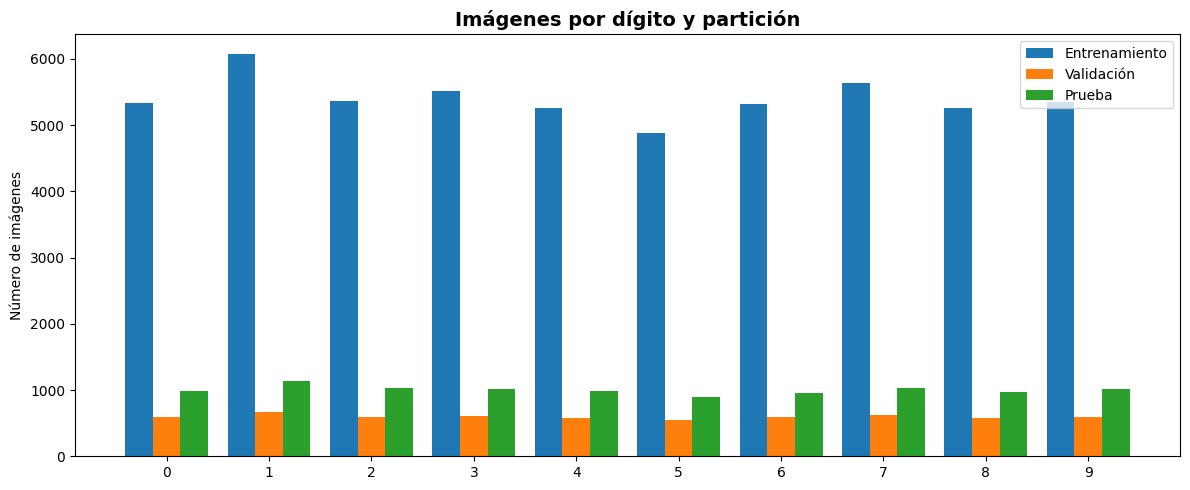

In [ ]:
x = np.arange(NUM_CLASSES)
plt.figure(figsize=(12, 5))
plt.bar(x - 0.27, tabla_clases["Entrenamiento"], width=0.27, label="Entrenamiento")
plt.bar(x, tabla_clases["Validacion"], width=0.27, label="Validacon")
plt.bar(x + 0.27, tabla_clases["Prueba"], width=0.27, label="Prueba")
plt.xticks(x, classes)
plt.title("Imagenes por dígito y particion", fontsize=14, fontweight="bold")
plt.ylabel("Número de imagenes")
plt.legend()
plt.tight_layout()
plt.show()

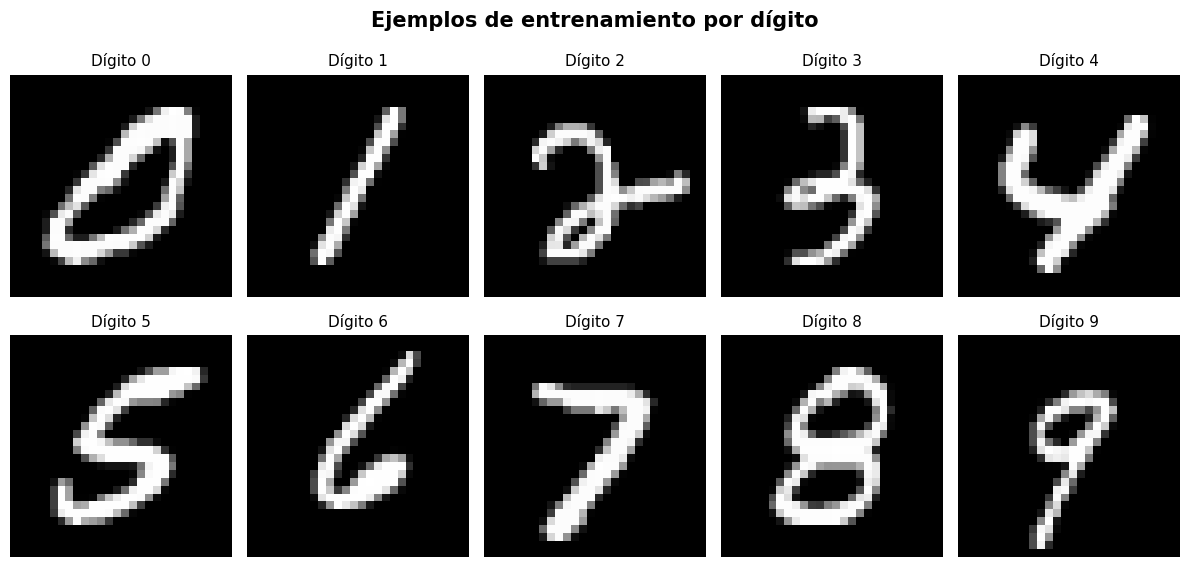

In [ ]:
fig, axs = plt.subplots(2, 5, figsize=(12, 6))
for clase, ax in enumerate(axs.flat):
    i = np.where(y_train == clase)[0][0]
    ax.imshow(X_train[i][:, :, 0], cmap="gray")
    ax.set_title(f"Digito {classes[clase]}", fontsize=11)
    ax.axis("off")
plt.suptitle("Ejemplos de entrenamiento por digito", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# 6. Diseño de las tres arquitecturas (Paso 1)

Se proponen tres arquitecturas con distinto grado de complejidad. Se usan las propuestas de estas: número de capas, neuronas y Dropout de cada una. La capa de salida tiene 10 neuronas con softmax, una por dígito.

| Propuesta | Capas ocultas | Neuronas | Dropout | Parámetros | Justificación |
|---|---|---|---|---|---|
| A (red simple) | 1 | 64 | 0,2 | 50 890 | Propuesta A del PDF: una capa oculta pequeña (64 neuronas) con Dropout 0,2. |
| B (red intermedia) | 1 | 128 | 0,5 | 101 770 | Propuesta B del PDF: una capa oculta de 128 neuronas con Dropout 0,5. |
| C (red profunda) | 2 | 256 y 128 | 0,3 en cada capa | 235 146 | Propuesta C del PDF: dos capas ocultas con Dropout 0,3 en cada una. |

# 7. Modelo A: red simple

Una capa oculta de 64 neuronas con Dropout(0,2).

**Función de resumen.** Al terminar cada entrenamiento se imprimen las métricas finales, con los mejores pesos restaurados, y si el modelo cumple cada criterio.

In [ ]:
RESULTADOS = {}

def resumen_modelo(clave, modelo, history, t):
    n_ep = len(history.history["loss"])
    mejor = int(np.argmin(history.history["val_loss"])) + 1

    _, acc_tr = modelo.evaluate(X_train, y_train, batch_size=BATCH_SIZE, verbose=0)
    val_loss, acc_va = modelo.evaluate(X_val, y_val, batch_size=BATCH_SIZE, verbose=0)
    brecha = acc_tr - acc_va

    RESULTADOS[clave] = {
        "Parametros": modelo.count_params(),
        "Épocas ejecutadas": n_ep,
        "Mejor epoca": mejor,
        "Precision entrenamiento (%)": acc_tr * 100,
        "Precision validación (%)": acc_va * 100,
        "Brecha (pp)": brecha * 100,
        "Pérdida validacion": val_loss,
        "Tiempo (s)": t,
        "Cumple precision": bool(acc_va >= 0.975),
        "Cumple brecha": bool(brecha <= 0.015),
        "Cumple eficiencia": bool(n_ep < EPOCHS),
    }
    r = RESULTADOS[clave]

    print(f"Modelo {clave} | Epocas ejecutadas: {n_ep} de {EPOCHS} | Mejor época: {mejor} | Tiempo: {t:.1f} s")
    print(f"  Precision entrenamiento: {acc_tr * 100:.2f} % | Precisión validacion: {acc_va * 100:.2f} % | "
          f"Brecha de sobreajuste: {brecha * 100:.2f} pp | Perdida validación: {val_loss:.4f}")
    print(f"  Cumple precision ≥ 0.975: {r['Cumple precision']} | "
          f"Cumple brecha ≤ 0.015: {r['Cumple brecha']} | "
          f"Cumple eficiencia (< {EPOCHS} epocas): {r['Cumple eficiencia']}")

In [ ]:
modelo_a = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="Entrada"),
    tf.keras.layers.Flatten(name="Aplanado"),
    tf.keras.layers.Dense(64, activation="relu", name="Densa_1"),
    tf.keras.layers.Dropout(0.2, name="Dropout_1"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="Salida"),
], name="Modelo_A")

modelo_a.summary()

Model: "Modelo_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Aplanado (Flatten)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    mode="min"
)

t0 = time()
history_a = modelo_a.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)
t_a = time() - t0
print(f"Épocas ejecutadas: {len(history_a.history['loss'])} de {EPOCHS} | Tiempo: {t_a:.1f} s")

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8755 - loss: 0.4333 - val_accuracy: 0.9365 - val_loss: 0.2198
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9343 - loss: 0.2238 - val_accuracy: 0.9532 - val_loss: 0.1644
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9469 - loss: 0.1778 - val_accuracy: 0.9602 - val_loss: 0.1366
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9556 - loss: 0.1492 - val_accuracy: 0.9663 - val_loss: 0.1212
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9601 - loss: 0.1321 - val_accuracy: 0.9708 - val_loss: 0.1088
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9634 - loss: 0.1199 - val_accuracy: 0.9693 - val_loss: 0.1035
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9659 - loss: 0.1097 - val_accuracy: 0.9708 - val_loss: 0.1004
Epoch 8/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9687 - loss: 0.1007 - val_accuracy: 0.

In [ ]:
resumen_modelo("A", modelo_a, history_a, t_a)

Modelo A | Épocas ejecutadas: 15 de 30 | Mejor época: 12 | Tiempo: 58.0 s
  Precisión entrenamiento: 98.90 % | Precisión validación: 97.52 % | Brecha de sobreajuste: 1.38 pp | Pérdida validación: 0.0880
  Cumple precisión ≥ 0.975: True | Cumple brecha ≤ 0.015: True | Cumple eficiencia (< 30 épocas): True


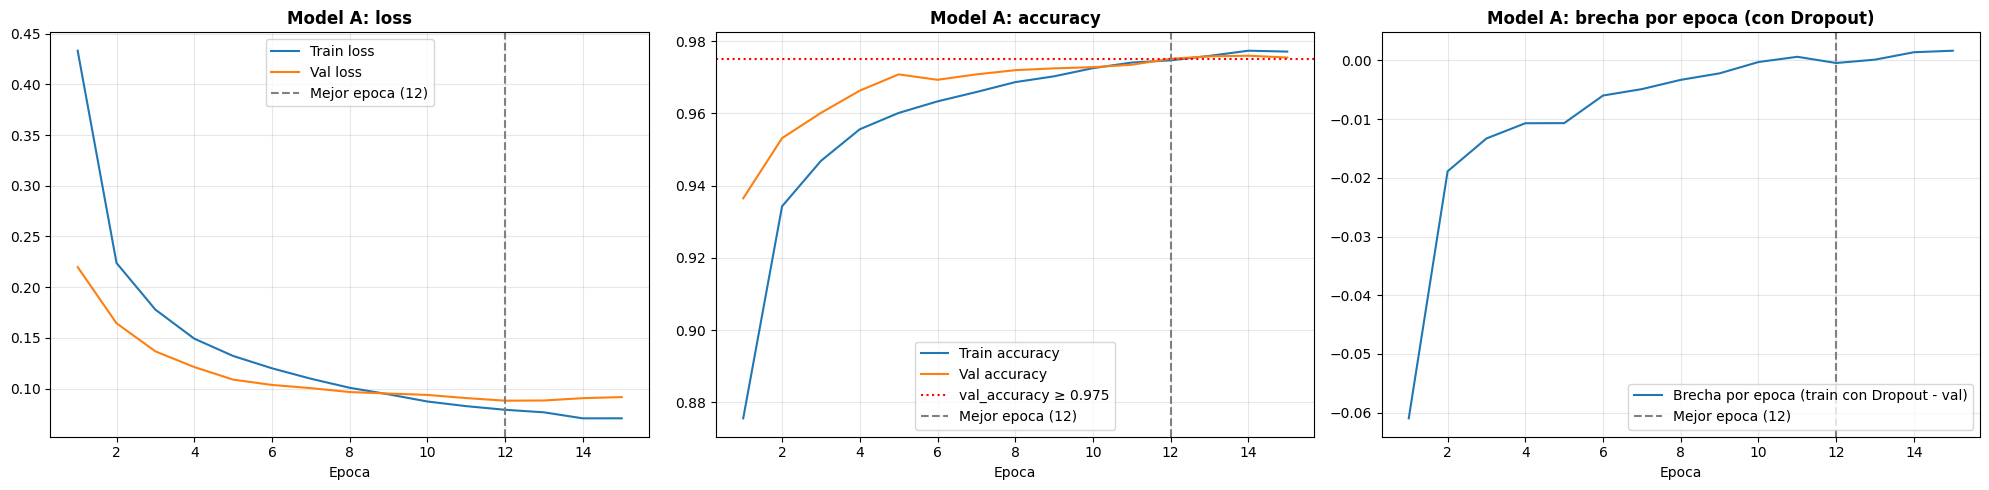

In [ ]:
def graficar_curvas(history, titulo):
    epocas = np.arange(1, len(history.history["loss"]) + 1)
    mejor = int(np.argmin(history.history["val_loss"])) + 1
    gap = np.array(history.history["accuracy"]) - np.array(history.history["val_accuracy"])

    fig, axs = plt.subplots(1, 3, figsize=(20, 5))

    axs[0].plot(epocas, history.history["loss"], label="Train loss")
    axs[0].plot(epocas, history.history["val_loss"], label="Val loss")
    axs[0].axvline(mejor, color="gray", ls="--", label=f"Mejor epoca ({mejor})")
    axs[0].set_title(f"{titulo}: loss", fontweight="bold")
    axs[0].set_xlabel("Epoca")
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)

    axs[1].plot(epocas, history.history["accuracy"], label="Train accuracy")
    axs[1].plot(epocas, history.history["val_accuracy"], label="Val accuracy")
    axs[1].axhline(0.975, color="red", ls=":", label="val_accuracy ≥ 0.975")
    axs[1].axvline(mejor, color="gray", ls="--", label=f"Mejor epoca ({mejor})")
    axs[1].set_title(f"{titulo}: accuracy", fontweight="bold")
    axs[1].set_xlabel("Epoca")
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)

    axs[2].plot(epocas, gap, label="Brecha por epoca (train con Dropout - val)")
    axs[2].axvline(mejor, color="gray", ls="--", label=f"Mejor epoca ({mejor})")
    axs[2].set_title(f"{titulo}: brecha por epoca (con Dropout)", fontweight="bold")
    axs[2].set_xlabel("Epoca")
    axs[2].legend()
    axs[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

graficar_curvas(history_a, "Model A")

**Análisis de las curvas del modelo A**

El mínimo de val_loss está en la época 12 (0,0880) y EarlyStopping detuvo el entrenamiento en la época 15, tres épocas después, como indica la paciencia. Se restauraron los pesos de la época 12, con precisión de validación de 97,52 %. Se detuvo antes de la época 30, así que cumple la eficiencia.

La precisión de validación siguió subiendo hasta 97,60 % en la época 14, pero val_loss ya no mejoraba. El criterio de parada usa la pérdida, no la precisión.

Sobre la brecha: la gráfica muestra la brecha por época, con Dropout activo y como promedio de los lotes de cada época, y está cerca de cero en la época 12. La brecha del criterio es 1,38 pp, porque se mide con los pesos restaurados y el Dropout desactivado. Hay dos factores que hacen que la gráfica subestime la brecha: el Dropout reduce la precisión de entrenamiento (97,47 % en la época 12, frente a 98,90 % sin Dropout), y el promedio de la época incluye lotes anteriores, cuando el modelo todavía mejoraba. Con esta corrida no se puede separar cuánto aporta cada uno.

# 8. Modelo B: red intermedia

Una capa oculta de 128 neuronas con Dropout(0,5).

In [ ]:
modelo_b = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="Entrada"),
    tf.keras.layers.Flatten(name="Aplanado"),
    tf.keras.layers.Dense(128, activation="relu", name="Densa_1"),
    tf.keras.layers.Dropout(0.5, name="Dropout_1"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="Salida"),
], name="Modelo_B")

modelo_b.summary()

Model: "Modelo_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Aplanado (Flatten)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    mode="min"
)

t0 = time()
history_b = modelo_b.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)
t_b = time() - t0
print(f"Épocas ejecutadas: {len(history_b.history['loss'])} de {EPOCHS} | Tiempo: {t_b:.1f} s")

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8648 - loss: 0.4553 - val_accuracy: 0.9417 - val_loss: 0.2067
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9269 - loss: 0.2504 - val_accuracy: 0.9545 - val_loss: 0.1594
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9414 - loss: 0.2016 - val_accuracy: 0.9622 - val_loss: 0.1330
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9471 - loss: 0.1773 - val_accuracy: 0.9653 - val_loss: 0.1237
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9512 - loss: 0.1589 - val_accuracy: 0.9683 - val_loss: 0.1096
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9569 - loss: 0.1456 - val_accuracy: 0.9710 - val_loss: 0.1027
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9585 - loss: 0.1374 - val_accuracy: 0.9717 - val_loss: 0.0988
Epoch 8/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9612 - loss: 0.1262 - val_accuracy: 0.

In [ ]:
resumen_modelo("B", modelo_b, history_b, t_b)

Modelo B | Épocas ejecutadas: 18 de 30 | Mejor época: 15 | Tiempo: 94.9 s
  Precisión entrenamiento: 99.03 % | Precisión validación: 97.62 % | Brecha de sobreajuste: 1.41 pp | Pérdida validación: 0.0851
  Cumple precisión ≥ 0.975: True | Cumple brecha ≤ 0.015: True | Cumple eficiencia (< 30 épocas): True


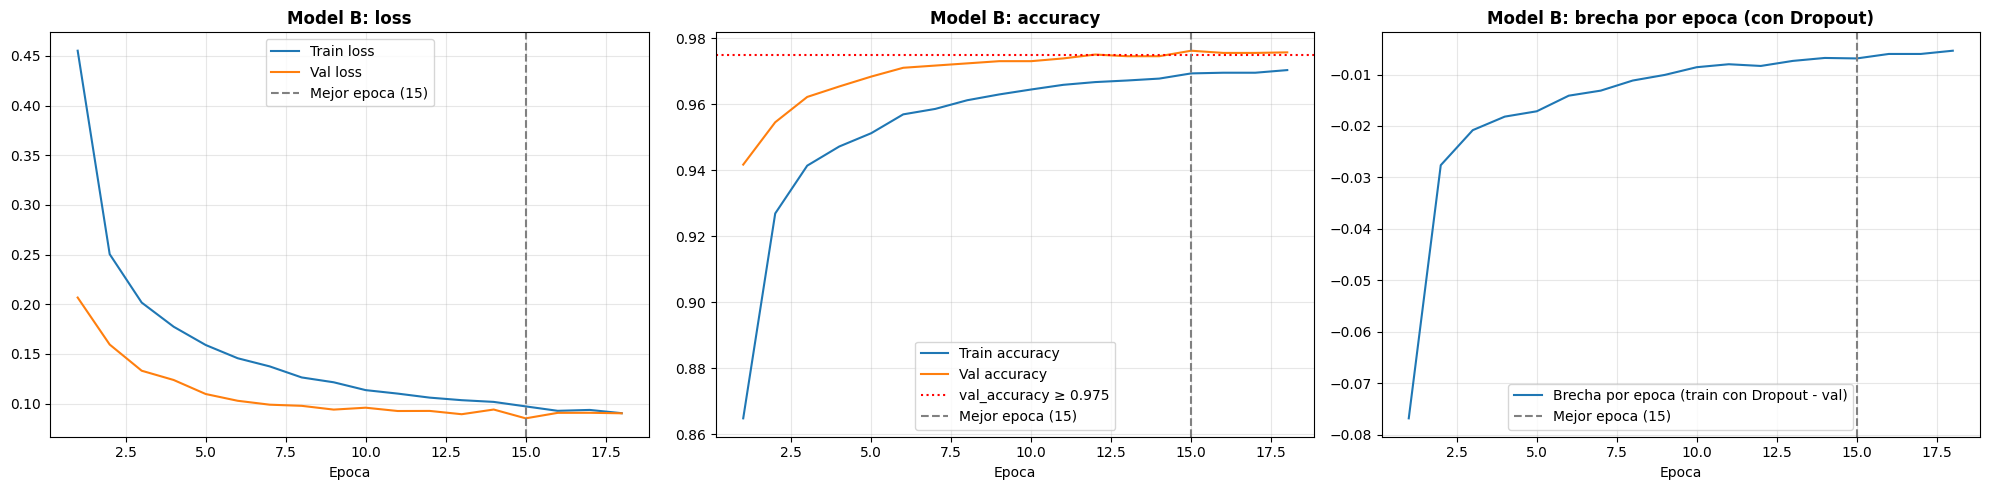

In [ ]:
graficar_curvas(history_b, "Model B")

**Análisis de las curvas del modelo B**

El mínimo de val_loss está en la época 15 (0,0851), con precisión de validación de 97,62 %. EarlyStopping se detuvo en la época 18, tres épocas después, y restauró los pesos de la época 15. Se detuvo antes de la época 30, así que cumple la eficiencia.

En la época 15, la brecha de la gráfica (con Dropout activo y promedio por época) es −0,69 pp, mientras que la del criterio, medida con Dropout desactivado, es 1,41 pp. La diferencia es mayor que en A (2,1 pp frente a 1,4 pp). Parte de esa diferencia puede deberse al Dropout de 0,5, que apaga más neuronas durante el entrenamiento, pero el promedio por época también influye y no se puede separar con esta corrida.

# 9. Modelo C: red profunda

Dos capas ocultas de 256 y 128 neuronas, con Dropout(0,3) después de cada una.

In [ ]:
modelo_c = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="Entrada"),
    tf.keras.layers.Flatten(name="Aplanado"),
    tf.keras.layers.Dense(256, activation="relu", name="Densa_1"),
    tf.keras.layers.Dropout(0.3, name="Dropout_1"),
    tf.keras.layers.Dense(128, activation="relu", name="Densa_2"),
    tf.keras.layers.Dropout(0.3, name="Dropout_2"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="Salida"),
], name="Modelo_C")

modelo_c.summary()

Model: "Modelo_C"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Aplanado (Flatten)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_c.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    mode="min"
)

t0 = time()
history_c = modelo_c.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)
t_c = time() - t0
print(f"Épocas ejecutadas: {len(history_c.history['loss'])} de {EPOCHS} | Tiempo: {t_c:.1f} s")

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.8958 - loss: 0.3433 - val_accuracy: 0.9585 - val_loss: 0.1419
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9534 - loss: 0.1559 - val_accuracy: 0.9667 - val_loss: 0.1184
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9636 - loss: 0.1179 - val_accuracy: 0.9703 - val_loss: 0.1067
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9703 - loss: 0.0959 - val_accuracy: 0.9740 - val_loss: 0.0908
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9745 - loss: 0.0832 - val_accuracy: 0.9758 - val_loss: 0.0881
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9773 - loss: 0.0733 - val_accuracy: 0.9762 - val_loss: 0.0901
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9787 - loss: 0.0667 - val_accuracy: 0.9793 - val_loss: 0.0848
Epoch 8/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9799 - loss: 0.0626 - val_accuracy

In [ ]:
resumen_modelo("C", modelo_c, history_c, t_c)

Modelo C | Épocas ejecutadas: 12 de 30 | Mejor época: 9 | Tiempo: 103.4 s
  Precisión entrenamiento: 99.42 % | Precisión validación: 98.12 % | Brecha de sobreajuste: 1.30 pp | Pérdida validación: 0.0753
  Cumple precisión ≥ 0.975: True | Cumple brecha ≤ 0.015: True | Cumple eficiencia (< 30 épocas): True


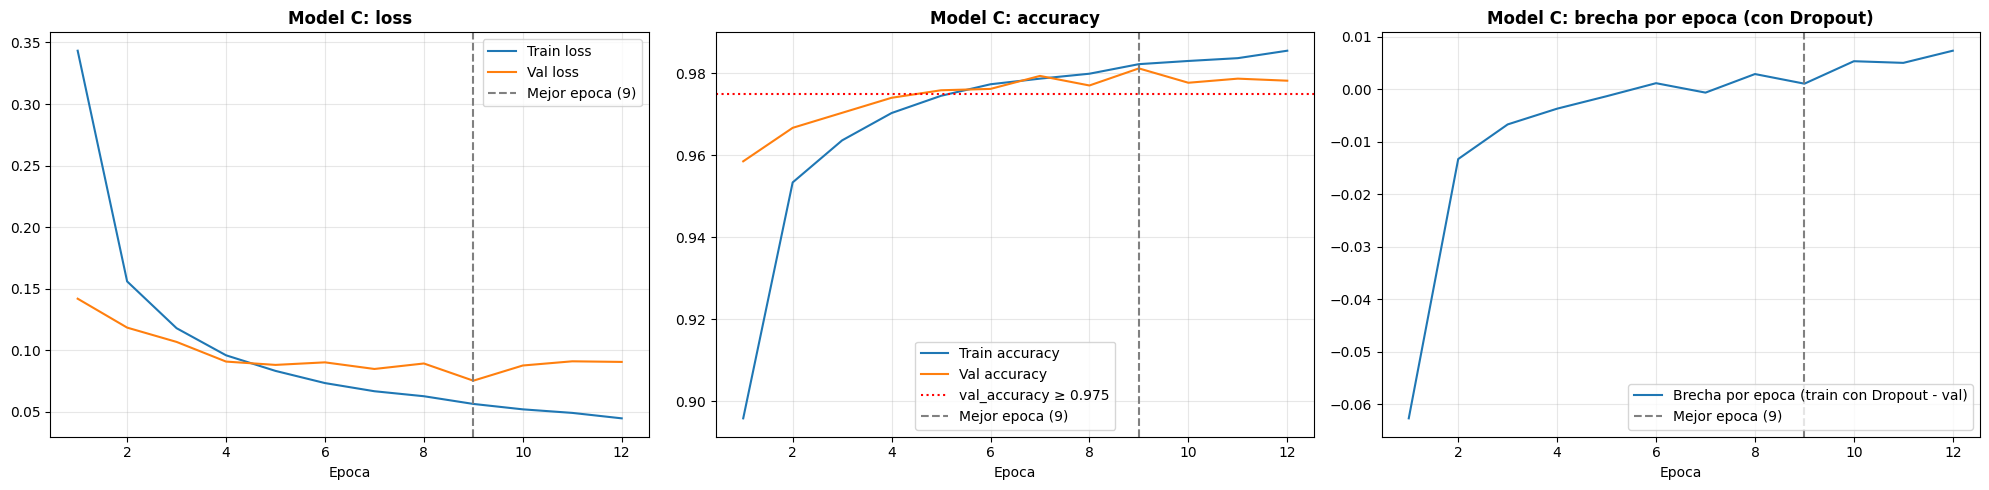

In [ ]:
graficar_curvas(history_c, "Model C")

**Análisis de las curvas del modelo C**

El mínimo de val_loss está en la época 9 (0,0753), con precisión de validación de 98,12 %, el valor más alto de la corrida. EarlyStopping se detuvo en la época 12, tres épocas después. Se detuvo antes de la época 30, así que cumple la eficiencia.

La brecha de la gráfica (con Dropout activo y promedio por época) pasa de +0,10 pp en la época 9 a +0,73 pp en la época 12, así que sí se ve crecer el sobreajuste después del mínimo de validación. La brecha del criterio, con Dropout desactivado, es 1,30 pp. La diferencia de 1,2 pp en la época 9 se debe al Dropout y al promedio por época; con esta corrida no se pueden separar.

# 10. Umbrales mínimos y criterios de aceptación (Paso 3)

Los criterios se evalúan con los pesos de la mejor época, que EarlyStopping restaura al final del entrenamiento. La brecha es Precisión de entrenamiento − Precisión de validación.

In [ ]:
acc_tr_a = accuracy_score(y_train, np.argmax(modelo_a.predict(X_train, verbose=0), axis=1))
acc_va_a = accuracy_score(y_val, np.argmax(modelo_a.predict(X_val, verbose=0), axis=1))

acc_tr_b = accuracy_score(y_train, np.argmax(modelo_b.predict(X_train, verbose=0), axis=1))
acc_va_b = accuracy_score(y_val, np.argmax(modelo_b.predict(X_val, verbose=0), axis=1))

acc_tr_c = accuracy_score(y_train, np.argmax(modelo_c.predict(X_train, verbose=0), axis=1))
acc_va_c = accuracy_score(y_val, np.argmax(modelo_c.predict(X_val, verbose=0), axis=1))

def fila(nombre, modelo, history, t, acc_tr, acc_va):
    n_ep = len(history.history["loss"])
    brecha = acc_tr - acc_va
    return {
        "Modelo": nombre,
        "Parámetros": modelo.count_params(),
        "Epocas ejecutadas": n_ep,
        "Mejor época": int(np.argmin(history.history["val_loss"])) + 1,
        "Precision entrenamiento (%)": acc_tr * 100,
        "Precision validación (%)": acc_va * 100,
        "Brecha (pp)": brecha * 100,
        "Pérdida validacion": min(history.history["val_loss"]),
        "Tiempo (s)": t,
        "Cumple precision": acc_va >= 0.975,
        "Cumple brecha": brecha <= 0.015,
        "Cumple eficiencia": n_ep < EPOCHS,
    }

df_comp = pd.DataFrame([
    fila("A", modelo_a, history_a, t_a, acc_tr_a, acc_va_a),
    fila("B", modelo_b, history_b, t_b, acc_tr_b, acc_va_b),
    fila("C", modelo_c, history_c, t_c, acc_tr_c, acc_va_c),
]).set_index("Modelo")
df_comp["Cumple todos"] = df_comp[["Cumple precision", "Cumple brecha", "Cumple eficiencia"]].all(axis=1)
display(df_comp.round(4))

aceptados = df_comp[df_comp["Cumple todos"]]
if aceptados.empty:
    seleccionado = None
    print("Ningún modelo cumple los tres criterios. Se reportan los resultados sin alterarlos.")
else:
    seleccionado = aceptados["Pérdida validacion"].idxmin()
    print("Modelos aceptados:", list(aceptados.index))
    print(f"Modelo seleccionado: {seleccionado} (menor pérdida de validación entre los aceptados)")

,Parámetros,Épocas ejecutadas,Mejor época,Precisión entrenamiento (%),Precisión validación (%),Brecha (pp),Pérdida validación,Tiempo (s),Cumple precisión,Cumple brecha,Cumple eficiencia,Cumple todos
Modelo,,,,,,,,,,,,
A,50890,15,12,98.8981,97.5167,1.3815,0.0880,58.0239,True,True,True,True
B,101770,18,15,99.0278,97.6167,1.4111,0.0851,94.8632,True,True,True,True
C,235146,12,9,99.4185,98.1167,1.3019,0.0753,103.4428,True,True,True,True


Modelos aceptados: ['A', 'B', 'C']
Modelo seleccionado: C (menor pérdida de validación entre los aceptados)


**Análisis de los umbrales**

| Modelo | Precisión de validación (≥ 97,5 %) | Brecha (≤ 1,5 pp) | Épocas (< 30) | Cumple los tres |
|---|---|---|---|---|
| A |  97,52 % (margen +0,02) |  1,38 pp (margen −0,12) |  15 | Sí |
| B |  97,62 % (margen +0,12) |  1,41 pp (margen −0,09) |  18 | Sí |
| C |  98,12 % (margen +0,62) |  1,30 pp (margen −0,20) |  12 | Sí |

Los tres modelos cumplen los tres criterios en esta corrida. El margen más justo es el de A: su precisión de validación supera el umbral por solo 0,02 pp. C tiene el margen más amplio en ambos criterios. El modelo seleccionado es C, porque tiene la menor pérdida de validación entre los aceptados (0,0753, frente a 0,0851 de B y 0,0880 de A).

# 11. Comparación de resultados (Paso 4)

Se muestran la tabla comparativa y los gráficos que contraponen la precisión y la pérdida de validación de las tres arquitecturas.

In [ ]:
display(df_comp[[
    "Parámetros", "Epocas ejecutadas", "Mejor época",
    "Precisión entrenamiento (%)", "Precision validación (%)", "Brecha (pp)",
    "Pérdida validacion", "Tiempo (s)"
]].round(4))

,Parámetros,Épocas ejecutadas,Mejor época,Precisión entrenamiento (%),Precisión validación (%),Brecha (pp),Pérdida validación,Tiempo (s)
Modelo,,,,,,,,
A,50890,15,12,98.8981,97.5167,1.3815,0.0880,58.0239
B,101770,18,15,99.0278,97.6167,1.4111,0.0851,94.8632
C,235146,12,9,99.4185,98.1167,1.3019,0.0753,103.4428


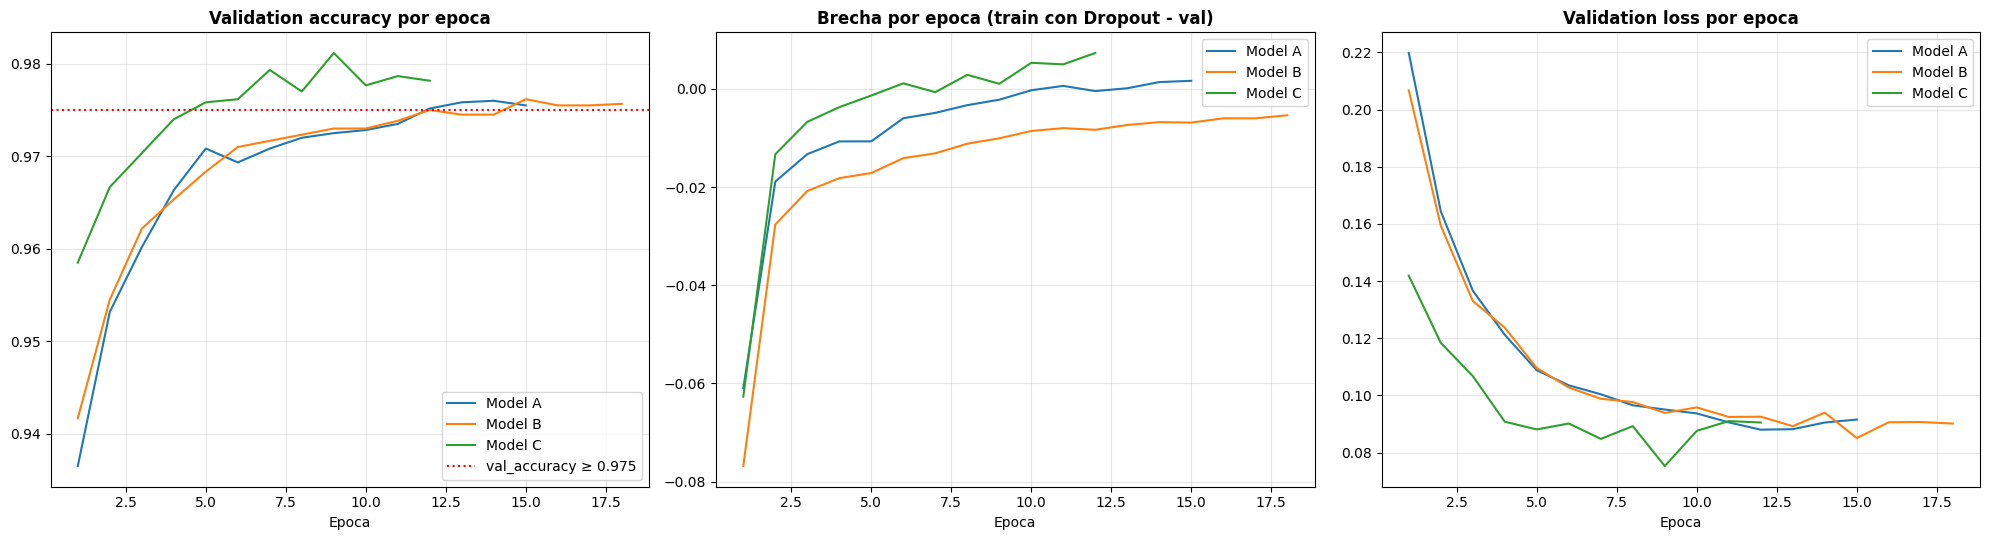

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5))
for nombre, h in [("Model A", history_a), ("Model B", history_b), ("Model C", history_c)]:
    ep = np.arange(1, len(h.history["val_accuracy"]) + 1)
    gap = np.array(h.history["accuracy"]) - np.array(h.history["val_accuracy"])
    axs[0].plot(ep, h.history["val_accuracy"], label=nombre)
    axs[1].plot(ep, gap, label=nombre)
    axs[2].plot(ep, h.history["val_loss"], label=nombre)

axs[0].axhline(0.975, color="red", ls=":", label="val_accuracy ≥ 0.975")
axs[0].set_title("Validation accuracy por epoca", fontweight="bold")
axs[1].set_title("Brecha por epoca (train con Dropout - val)", fontweight="bold")
axs[2].set_title("Validation loss por epoca", fontweight="bold")
for ax in axs:
    ax.set_xlabel("Epoca")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Análisis comparativo**

1. **Velocidad de convergencia.** C alcanzó su mejor pérdida de validación en la época 9, antes que A (época 12) y B (época 15). Los tres modelos detuvieron el entrenamiento entre las épocas 12 y 18, todas antes de la 30.

2. **Efecto de la complejidad.** C tiene dos capas ocultas y 235 146 parámetros; A y B tienen una capa oculta y 50 890 y 101 770 parámetros. C obtuvo la mayor precisión de validación (98,12 %), la menor pérdida (0,0753) y la menor brecha (1,30 pp). En esta corrida, más capacidad mejoró los tres indicadores, aunque no se puede separar el efecto de la profundidad del efecto de tener más parámetros.

3. **Efecto del Dropout.** A (64 neuronas, Dropout 0,2) y B (128 neuronas, Dropout 0,5) difieren en dos cosas a la vez. B tiene mayor precisión de validación (97,62 % frente a 97,52 %) y menor pérdida (0,0851 frente a 0,0880), pero su brecha es ligeramente mayor (1,41 frente a 1,38 pp). Con más Dropout y más neuronas, la brecha no bajó en esta corrida, así que el efecto del Dropout no se ve con claridad en la comparación entre A y B.

4. **Limitaciones.** Las diferencias entre A y B son pequeñas (0,10 pp en validación y 0,03 pp en brecha) y podrían no mantenerse en otra corrida. La configuración final (batch 64, paciencia 3, validación de 10 %) se eligió después de probar varias combinaciones de batch, learning rate y paciencia sobre validación.

# 12. Evaluación en el conjunto de prueba

El conjunto de prueba no se usa para ajustar los modelos ni para elegir la arquitectura. Se reporta como evaluación final. Las clases de MNIST están relativamente equilibradas, pero también se reporta el F1 macro, que pesa todas las clases por igual.

In [ ]:
def calcular_metricas(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

y_pred_a = np.argmax(modelo_a.predict(X_test, verbose=0), axis=1)
y_pred_b = np.argmax(modelo_b.predict(X_test, verbose=0), axis=1)
y_pred_c = np.argmax(modelo_c.predict(X_test, verbose=0), axis=1)

met_a = calcular_metricas(y_test, y_pred_a)
met_b = calcular_metricas(y_test, y_pred_b)
met_c = calcular_metricas(y_test, y_pred_c)

df_test = pd.DataFrame({"Modelo A": met_a, "Modelo B": met_b, "Modelo C": met_c}).T
display(df_test.round(4))

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
Modelo A,0.9744,0.9741,0.9744,0.9742,0.9744
Modelo B,0.9773,0.9771,0.9771,0.9771,0.9773
Modelo C,0.9816,0.9815,0.9814,0.9815,0.9816


Reporte de clasificación (modelo C)
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.97      0.98       974
           9       0.98      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



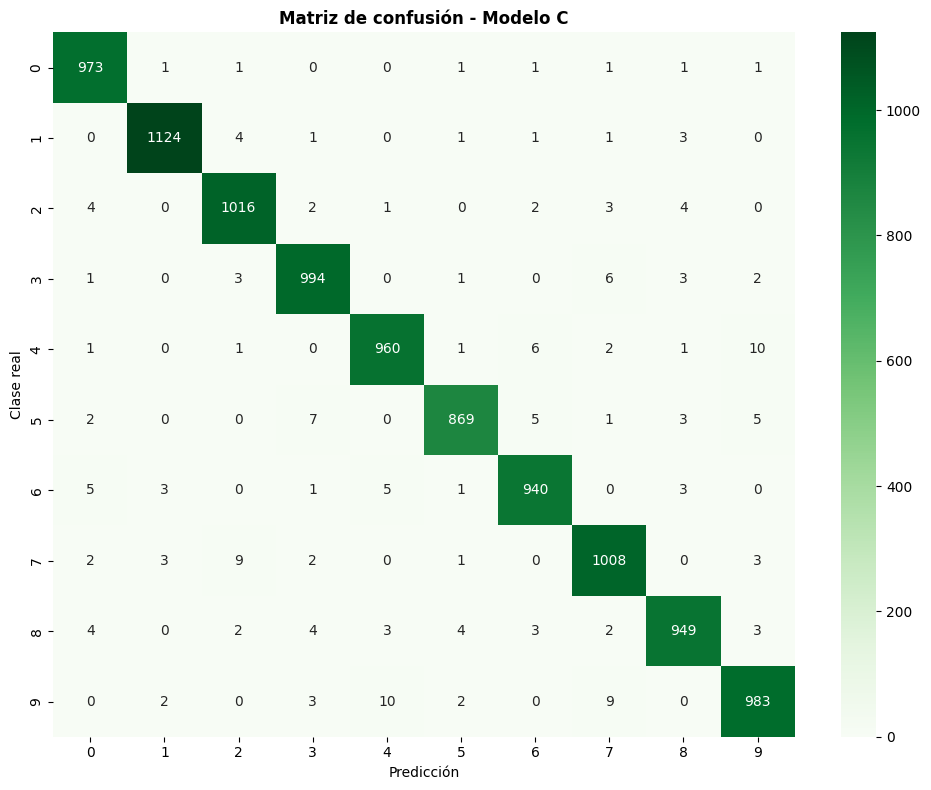

In [ ]:
pred_sel = {"A": y_pred_a, "B": y_pred_b, "C": y_pred_c}

if seleccionado is not None:
    print(f"Reporte de clasificacion (modelo {seleccionado})")
    print(classification_report(y_test, pred_sel[seleccionado], target_names=classes, zero_division=0))

    cm = confusion_matrix(y_test, pred_sel[seleccionado])
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=classes, yticklabels=classes)
    plt.title(f"Matriz de confusion - Modelo {seleccionado}", fontweight="bold")
    plt.ylabel("Clase real")
    plt.xlabel("Predicción")
    plt.tight_layout()
    plt.show()

**Interpretación de la evaluación en prueba**

La accuracy de prueba es 97,44 % (A), 97,73 % (B) y 98,16 % (C). Frente a la validación, la diferencia es de −0,08 pp, +0,11 pp y +0,04 pp. Las estimaciones de validación son representativas y ningún modelo cae de forma notable en prueba. El F1 macro (97,42 %, 97,71 % y 98,15 %) es casi igual a la accuracy, lo que confirma que el desbalance leve de las clases no distorsiona la métrica.

En el reporte por dígito del modelo C, el F1 va de 0,98 a 0,99 en todas las clases. La recall más baja es de 0,97 en los dígitos 5, 8 y 9. En la matriz de confusión, los errores más frecuentes son 4 clasificado como 9 (10 casos), 9 clasificado como 4 (10 casos), 9 como 7 (9 casos), 7 como 2 (9 casos) y 5 como 3 (7 casos). Son pares de dígitos que suelen confundirse por la forma del trazo.

# 13. Conclusiones

**Cumplimiento:** en esta corrida, los tres modelos cumplen los tres criterios: precisión de validación ≥ 97,5 %, brecha ≤ 1,5 pp y detención antes de la época 30. El modelo seleccionado es C, con la menor pérdida de validación entre los aceptados.

**Complejidad:** el modelo con dos capas ocultas (C) obtuvo los mejores resultados en precisión, pérdida y brecha. Entre A y B, que tienen una capa oculta, la diferencia es mínima.

**Dropout con EarlyStopping:** en los tres modelos, EarlyStopping detuvo el entrenamiento tres épocas después del mínimo de la pérdida de validación (paciencia 3) y restauró los pesos de esa época. El Dropout de 0,5 de B no redujo la brecha frente al de 0,2 de A en esta corrida.

**Limitaciones:** es una sola corrida. Los márgenes de A y B son pequeños, y la configuración final se eligió después de varias pruebas sobre validación. La brecha de la gráfica (con Dropout activo) no coincide con la del criterio (sin Dropout). Los resultados corresponden a MNIST y no se extrapolan a otros conjuntos.

---

